# UrbanMind — EDA, Cleaning & Data Preparation

**Dataset:** `urbanmind_features_h3.csv` — 3,489 H3 hexagonal cells across Cairo, Egypt.

**Domains:** Population · Roads · Traffic · Transit · Air Quality · Green Space

| Step | Section |
|------|---------|
| 1 | Load Data |
| 2 | Data Quality Checks |
| 3 | Data Cleaning & Imputation |
| 4 | Exploratory Data Analysis (EDA) |
| 5 | Preprocessing & Feature Engineering |
| 6 | Final Model-Ready Data |

## 1. Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
%matplotlib inline

In [2]:
DATA_PATH = Path('urbanmind_features_h3.csv')
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f'Shape: {df.shape}  ({df.shape[0]} rows x {df.shape[1]} columns)')

Shape: (3489, 175)  (3489 rows x 175 columns)


In [3]:
display(df.head())

,h3_index,population_population_worldpop_2026,population_population_density_worldpop_2026,population_area_km2,population_cell_full_area_km2,population_cairo_intersection_ratio,population_latitude,population_longitude,population_reference_year,population_source,population_source_version,population_source_dataset,population_spatial_resolution_m,population_analytical_grid,population_crs,population_population_type,population_is_observed,population_is_estimated,population_quality_flag,population_production_date,population_doi,population_source_url,roads_latitude,roads_longitude,roads_area_km2,roads_road_length_km,roads_road_density_km_per_km2,roads_motorway_length_km,roads_trunk_length_km,roads_primary_road_length_km,...,air_quality_source_type,air_quality_source_version,air_quality_native_spatial_resolution_m,air_quality_analytical_grid,green_space_ndvi_mean_summer_2026,green_space_ndvi_median_summer_2026,green_space_ndvi_p90_summer_2026,green_space_ndvi_min_summer_2026,green_space_vegetated_fraction_summer_2026,green_space_ndvi_mean_annual_2026,green_space_ndvi_median_annual_2026,green_space_ndvi_p90_annual_2026,green_space_ndvi_min_annual_2026,green_space_vegetated_fraction_annual_2026,green_space_observation_count_2026,green_space_valid_pixel_fraction,green_space_vegetation_persistence_ratio,green_space_total_green_space_area_m2,green_space_public_green_space_area_m2,green_space_private_restricted_green_space_area_m2,green_space_agricultural_area_m2,green_space_natural_reserve_area_m2,green_space_number_of_public_parks,green_space_total_green_space_fraction,green_space_public_green_space_fraction,green_space_has_public_green_space,green_space_is_observed,green_space_is_derived,green_space_data_status,green_space_quality_flag
0,883e604925fffff,292.0810,3291.0400,0.0887,0.8665,0.1024,30.1974,31.4137,2026.0000,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0000,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.1974,31.4137,0.0887,2.1930,24.7100,0.0000,0.0000,0.0000,...,SATELLITE_TROPOSPHERIC_COLUMN_AND_IN_SITU_PROX...,S5P_L2_NO2_v02.04_EEAA_2026,5500.0000,H3_Resolution_8,0.1454,0.0970,0.3343,0.0213,0.2400,0.1459,0.0960,0.3445,0.0170,0.2333,4.0000,0.9725,1.0104,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,False,True,True,FINAL,HIGH_CONFIDENCE
1,883e604927fffff,1305.1258,2806.2800,0.4651,0.8664,0.5368,30.1935,31.4231,2026.0000,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0000,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.1935,31.4231,0.4651,4.9720,10.6900,0.0000,1.3340,0.0000,...,SATELLITE_TROPOSPHERIC_COLUMN_AND_IN_SITU_PROX...,S5P_L2_NO2_v02.04_EEAA_2026,5500.0000,H3_Resolution_8,0.0663,0.0589,0.0859,0.0006,0.0260,0.0663,0.0590,0.0837,-0.0055,0.0249,4.0000,0.9996,0.9983,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,False,True,True,FINAL,HIGH_CONFIDENCE
2,883e604933fffff,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.1960,31.4589,0.0242,0.4600,18.9900,0.0000,0.0000,0.0000,...,SATELLITE_TROPOSPHERIC_COLUMN_AND_IN_SITU_PROX...,S5P_L2_NO2_v02.04_EEAA_2026,5500.0000,H3_Resolution_8,0.1008,0.0656,0.2269,-0.0125,0.1223,0.0996,0.0670,0.2174,-0.0117,0.1158,4.0000,1.0000,0.9791,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,False,True,True,FINAL,HIGH_CONFIDENCE
3,883e604935fffff,203.3366,3299.9000,0.0616,0.8663,0.0711,30.1948,31.4410,2026.0000,WorldPop,v1,egy_pop_2026_CN_100m_R2025A_v1,100.0000,H3_Res8,EPSG:4326,Constrained,False,True,Estimated,2025-08-01,10.5258/SOTON/WP00839,https://data.worldpop.org/GIS/Population/Globa...,30.1948,31.4410,0.0616,1.9250,31.2400,0.0000,0.0000,0.0000,...,SATELLITE_TROPOSPHERIC_COLUMN_AND_IN_SITU_PROX...,S5P_L2_NO2_v02.04_EEAA_2026,5500.0000,H3_Resolution_8,0.0545,0.0514,0.0860,-0.0260,0.0030,0.0556,0.0529,0.0870,-0.0128,0.0022,4.0000,0.9992,0.9716,0.0000,0.0000,

## 2. Data Quality Checks

Before touching the data, we audit every possible data-quality issue:
- Feature types
- Duplicate rows / H3 IDs
- Missing values (count, percentage, visualisation, by domain)

> Findings here drive ALL decisions in Section 3 (Cleaning).

### 2.1 Feature types

In [4]:
numeric     = df.select_dtypes(include=np.number).columns.tolist()
categorical = df.select_dtypes(include=['object', 'category']).columns.tolist()
boolean     = df.select_dtypes(include='bool').columns.tolist()
print(f'Numeric: {len(numeric)} | Categorical: {len(categorical)} | Boolean: {len(boolean)}')

Numeric: 128 | Categorical: 47 | Boolean: 0


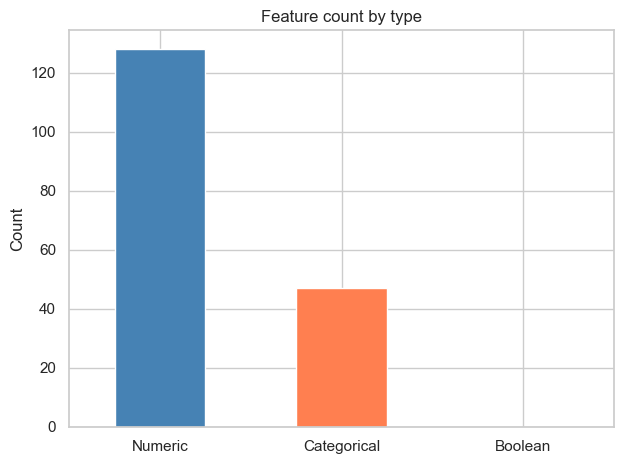

In [5]:
pd.Series({'Numeric': len(numeric), 'Categorical': len(categorical), 'Boolean': len(boolean)}
         ).plot.bar(color=['steelblue', 'coral', 'seagreen'])
plt.title('Feature count by type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.2 Duplicate rows

In [6]:
dup_rows = df.duplicated().sum()
print(f'Fully duplicate rows: {dup_rows}')

Fully duplicate rows: 0


### 2.3 Duplicate H3 identifiers

In [7]:
dup_h3 = df['h3_index'].duplicated().sum()
print(f'Duplicate H3 IDs: {dup_h3}')
if dup_h3 > 0:
    display(df[df['h3_index'].duplicated(keep=False)][['h3_index']].head(10))

Duplicate H3 IDs: 0


### 2.4 Missing values — count per feature

In [8]:
null_count = df.isna().sum().sort_values(ascending=False)
null_nonzero = null_count[null_count > 0]
print(f'Features with at least one missing value: {len(null_nonzero)}')
display(null_nonzero.to_frame('null_count'))

Features with at least one missing value: 174


,null_count
roads_avg_maxspeed,3470
traffic_avg_maxspeed,3470
traffic_population_per_lane_km_norm,3463
traffic_demand_capacity_pressure_index,3463
traffic_population_per_lane_km,3463
...,...
green_space_public_green_space_fraction,1
green_space_has_public_green_space,1
green_space_data_status,1
green_space_is_derived,1


### 2.5 Missing values — percentage per feature

In [9]:
null_pct = df.isna().mean().mul(100).sort_values(ascending=False)
null_pct_nonzero = null_pct[null_pct > 0]
display(null_pct_nonzero.to_frame('missing_%'))

,missing_%
roads_avg_maxspeed,99.4554
traffic_avg_maxspeed,99.4554
traffic_population_per_lane_km_norm,99.2548
traffic_demand_capacity_pressure_index,99.2548
traffic_population_per_lane_km,99.2548
...,...
green_space_public_green_space_fraction,0.0287
green_space_has_public_green_space,0.0287
green_space_data_status,0.0287
green_space_is_derived,0.0287


**Chart 1 (left):** Average missing % grouped by domain — easy to read at a glance.

**Chart 2 (right):** Per-feature missing % — only features with > 1 % missing shown,
coloured by domain with short readable labels.

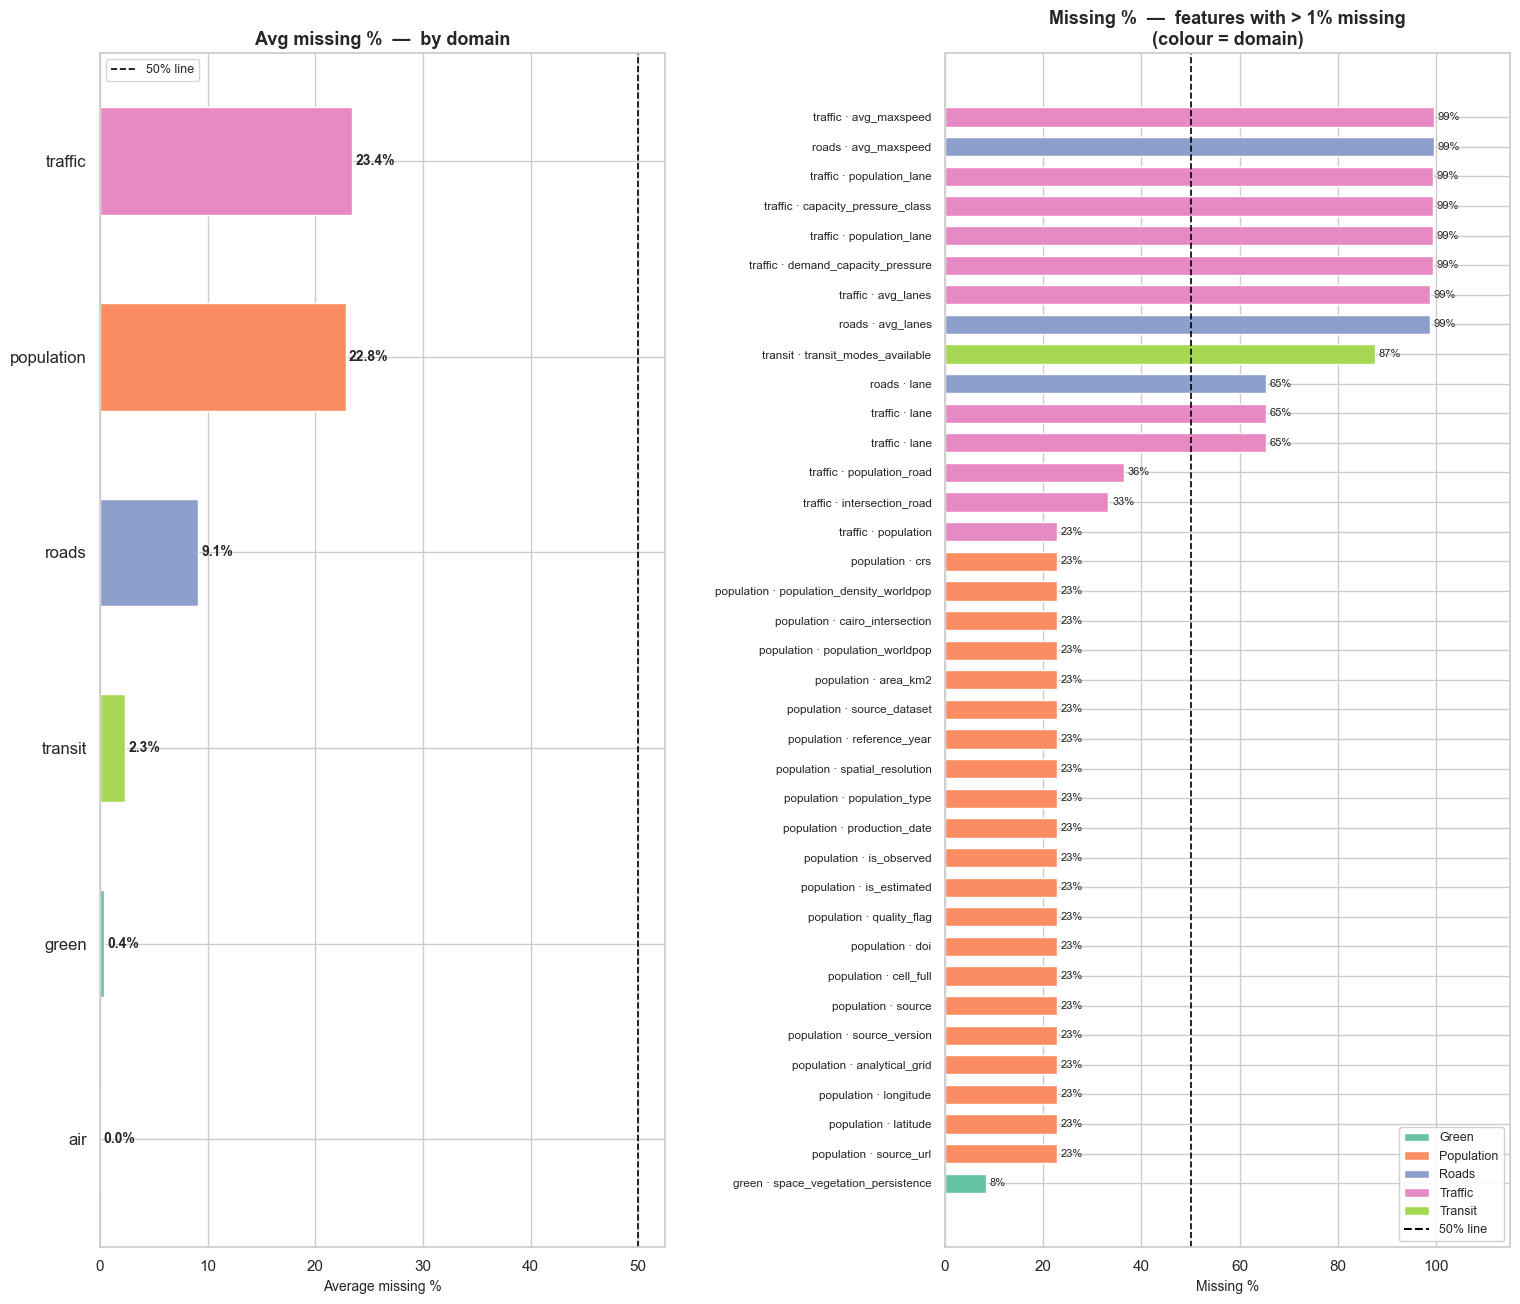

In [10]:
# ── Build domain-level missing % summary ────────────────────────────────
_tmp = null_pct_nonzero.reset_index()
_tmp.columns = ['feature', 'pct']
_tmp['domain'] = _tmp['feature'].str.split('_').str[0]
domain_miss = _tmp.groupby('domain')['pct'].mean().sort_values(ascending=True)

# ── Keep only features with > 1% missing for chart 2 ────────────────────
feat_sig = null_pct_nonzero[null_pct_nonzero > 1].sort_values(ascending=True)

# Short readable label: 'domain · key_words'
_skip = {'norm','index','km','m2','m','km2','2026','ratio','length',
         'count','fraction','per','area','_'}
def _short(col):
    parts = col.split('_')
    domain = parts[0]
    tail = [p for p in parts[1:] if p.lower() not in _skip]
    tail_str = '_'.join(tail[-3:]) if tail else '_'.join(parts[-2:])
    return f'{domain} · {tail_str}'

short_labels = [_short(c) for c in feat_sig.index]
domain_list  = [c.split('_')[0] for c in feat_sig.index]
unique_dom   = sorted(set(domain_list))
palette      = {d: plt.cm.Set2.colors[i % 8] for i, d in enumerate(unique_dom)}
bar_colors   = [palette[d] for d in domain_list]

# ── Figure ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, max(6, len(feat_sig) * 0.32 + 2)))

# LEFT — domain summary
colors_d = [palette.get(d, 'steelblue') for d in domain_miss.index]
axes[0].barh(range(len(domain_miss)), domain_miss.values,
             color=colors_d, edgecolor='white', height=0.55)
axes[0].set_yticks(range(len(domain_miss)))
axes[0].set_yticklabels(domain_miss.index, fontsize=12)
axes[0].axvline(50, color='black', linestyle='--', linewidth=1.2, label='50% line')
axes[0].set_title('Avg missing %  —  by domain', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Average missing %', fontsize=10)
axes[0].legend(fontsize=9)
for bar, val in zip(axes[0].patches, domain_miss.values):
    axes[0].text(bar.get_width() + 0.3,
                 bar.get_y() + bar.get_height() / 2,
                 f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')

# RIGHT — feature detail (>1% missing only, short labels)
n = len(feat_sig)
axes[1].barh(range(n), feat_sig.values, color=bar_colors,
             edgecolor='white', height=0.65)
axes[1].axvline(50, color='black', linestyle='--', linewidth=1.2)
axes[1].set_yticks(range(n))
axes[1].set_yticklabels(short_labels, fontsize=8.5)
axes[1].set_title('Missing %  —  features with > 1% missing\n(colour = domain)',
                  fontsize=13, fontweight='bold')
axes[1].set_xlabel('Missing %', fontsize=10)
axes[1].set_xlim(0, 115)
for i, val in enumerate(feat_sig.values):
    axes[1].text(val + 0.8, i, f'{val:.0f}%', va='center', fontsize=8)

from matplotlib.patches import Patch as _Patch
leg = [_Patch(facecolor=palette[d], label=d.title()) for d in unique_dom]
leg.append(plt.Line2D([0],[0], color='black', linestyle='--', label='50% line'))
axes[1].legend(handles=leg, loc='lower right', fontsize=9, framealpha=0.9)

plt.tight_layout(pad=3)
plt.show()

### 2.6 Missing values — summary by domain

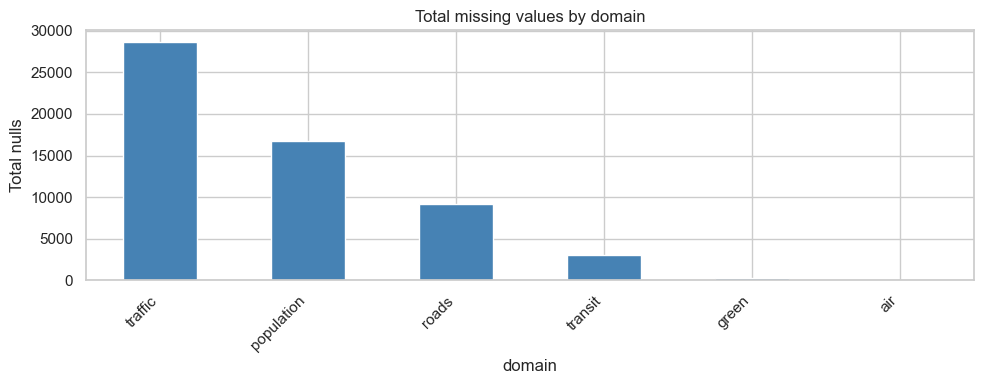

In [11]:
import matplotlib.pyplot as plt

null_nonzero = (
    df.isna()
      .sum()
      .loc[lambda s: s > 0]
      .rename("null_count")
)

miss_by_domain = (
    null_nonzero
    .rename_axis("feature")
    .reset_index()
    .assign(domain=lambda x: x["feature"].str.split("_").str[0])
    .groupby("domain")["null_count"]
    .sum()
    .sort_values(ascending=False)
)

ax = miss_by_domain.plot.bar(color="steelblue", figsize=(10, 4))
ax.set_title("Total missing values by domain")
ax.set_ylabel("Total nulls")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 2.7 Columns with > 50 % missing — candidates for dropping

In [12]:
high_miss = null_pct[null_pct > 50]
print(f'Columns with >50% missing ({len(high_miss)}):')
display(high_miss.to_frame('missing_%'))

Columns with >50% missing (12):


,missing_%
roads_avg_maxspeed,99.4554
traffic_avg_maxspeed,99.4554
traffic_population_per_lane_km_norm,99.2548
traffic_demand_capacity_pressure_index,99.2548
traffic_population_per_lane_km,99.2548
traffic_demand_capacity_pressure_class,99.2548
roads_avg_lanes,98.6529
traffic_avg_lanes,98.6529
transit_transit_modes_available,87.4463
traffic_lane_km_per_km2,65.3769


## 3. Data Cleaning & Imputation

Now that we know exactly what is wrong with the data, we fix it in order:

| Step | Action |
|------|--------|
| 3.1 | Remove duplicate H3 rows |
| 3.2 | Drop columns with > 50 % missing |
| 3.3 | Impute Population domain |
| 3.4 | Impute Roads domain |
| 3.5 | Impute Traffic domain |
| 3.6 | Impute Transit domain |
| 3.7 | Impute Air Quality domain |
| 3.8 | Impute Green Space domain |
| 3.9 | Verify — zero missing values remain |

**Imputation strategy:**
- **Numeric** columns → **Median** (robust to skewed / outlier-heavy distributions)
- **Categorical / Boolean** columns → **Mode** (most frequent observed value)

### 3.1 Remove duplicate H3 rows

In [13]:
clean = df.drop_duplicates('h3_index').copy()
print(f'Rows before dedup: {len(df)}  |  After dedup: {len(clean)}')

Rows before dedup: 3489  |  After dedup: 3489


### 3.2 Drop columns with > 50 % missing

In [14]:
high_miss_cols = null_pct[null_pct > 50].index.tolist()
clean = clean.drop(columns=high_miss_cols)
print(f'Dropped {len(high_miss_cols)} columns. New shape: {clean.shape}')
print('Dropped columns:', high_miss_cols)

Dropped 12 columns. New shape: (3489, 163)
Dropped columns: ['roads_avg_maxspeed', 'traffic_avg_maxspeed', 'traffic_population_per_lane_km_norm', 'traffic_demand_capacity_pressure_index', 'traffic_population_per_lane_km', 'traffic_demand_capacity_pressure_class', 'roads_avg_lanes', 'traffic_avg_lanes', 'transit_transit_modes_available', 'traffic_lane_km_per_km2', 'roads_lane_km', 'traffic_lane_km']


### 3.3 Impute — Population domain

> **Why?** 796 rows (23 %) in the population domain are missing because those
> H3 cells fall partially outside the Cairo administrative boundary.
> Median imputation preserves the distribution without introducing mean-bias from outliers.

In [15]:
pop_num = [c for c in clean.columns
           if c.startswith('population_')
           and clean[c].dtype != object
           and clean[c].dtype.name != 'bool']

pop_cat = [c for c in clean.columns
           if c.startswith('population_')
           and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in pop_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in pop_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('population_')]].isna().sum()
print('Population domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Population domain — missing after imputation:
None


C:\Users\DiaaAbdullah\AppData\Local\Temp\ipykernel_1292\3719994201.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean[col] = clean[col].fillna(mode_val[0])


### 3.4 Impute — Roads domain

In [16]:
roads_num = [c for c in clean.columns
             if c.startswith('roads_')
             and clean[c].dtype != object
             and clean[c].dtype.name != 'bool']

roads_cat = [c for c in clean.columns
             if c.startswith('roads_')
             and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in roads_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in roads_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('roads_')]].isna().sum()
print('Roads domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Roads domain — missing after imputation:
None


### 3.5 Impute — Traffic domain

In [17]:
traffic_num = [c for c in clean.columns
               if c.startswith('traffic_')
               and clean[c].dtype != object
               and clean[c].dtype.name != 'bool']

traffic_cat = [c for c in clean.columns
               if c.startswith('traffic_')
               and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in traffic_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in traffic_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('traffic_')]].isna().sum()
print('Traffic domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Traffic domain — missing after imputation:
None


C:\Users\DiaaAbdullah\AppData\Local\Temp\ipykernel_1292\960601214.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean[col] = clean[col].fillna(mode_val[0])


### 3.6 Impute — Transit domain

In [18]:
transit_num = [c for c in clean.columns
               if c.startswith('transit_')
               and clean[c].dtype != object
               and clean[c].dtype.name != 'bool']

transit_cat = [c for c in clean.columns
               if c.startswith('transit_')
               and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in transit_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in transit_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('transit_')]].isna().sum()
print('Transit domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Transit domain — missing after imputation:
None


C:\Users\DiaaAbdullah\AppData\Local\Temp\ipykernel_1292\1684705076.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean[col] = clean[col].fillna(mode_val[0])


### 3.7 Impute — Air Quality domain

In [19]:
aq_num = [c for c in clean.columns
          if c.startswith('air_quality_')
          and clean[c].dtype != object
          and clean[c].dtype.name != 'bool']

aq_cat = [c for c in clean.columns
          if c.startswith('air_quality_')
          and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in aq_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in aq_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('air_quality_')]].isna().sum()
print('Air Quality domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Air Quality domain — missing after imputation:
None


### 3.8 Impute — Green Space domain

In [20]:
gs_num = [c for c in clean.columns
          if c.startswith('green_space_')
          and clean[c].dtype != object
          and clean[c].dtype.name != 'bool']

gs_cat = [c for c in clean.columns
          if c.startswith('green_space_')
          and (clean[c].dtype == object or clean[c].dtype.name == 'bool')]

for col in gs_num:
    if clean[col].isna().any():
        clean[col] = clean[col].fillna(clean[col].median())

for col in gs_cat:
    if clean[col].isna().any():
        mode_val = clean[col].mode()
        if len(mode_val) > 0:
            clean[col] = clean[col].fillna(mode_val[0])

remaining = clean[[c for c in clean.columns if c.startswith('green_space_')]].isna().sum()
print('Green Space domain — missing after imputation:')
print(remaining[remaining > 0] if remaining.any() else 'None')

Green Space domain — missing after imputation:
None


C:\Users\DiaaAbdullah\AppData\Local\Temp\ipykernel_1292\3764706844.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  clean[col] = clean[col].fillna(mode_val[0])


### 3.9 Verify — zero missing values remain

In [21]:
total_remaining = clean.isna().sum().sum()
if total_remaining == 0:
    print('All missing values have been imputed successfully.')
else:
    still_missing = clean.isna().sum()
    still_missing = still_missing[still_missing > 0]
    print(f'{total_remaining} missing values still remain:')
    display(still_missing.to_frame('null_count'))

All missing values have been imputed successfully.


In [22]:
print(f'Clean dataset shape: {clean.shape}')
print(f'  Rows removed (dedup):     {len(df) - len(clean)}')
print(f'  Columns removed (>50%):   {len(high_miss_cols)}')

Clean dataset shape: (3489, 163)
  Rows removed (dedup):     0
  Columns removed (>50%):   12


## 4. Exploratory Data Analysis (EDA)

> All EDA is performed on the **cleaned, imputed** dataset `clean`.
> This ensures no missing values distort distributions or scatter plots.

### 4.1 Feature count by domain

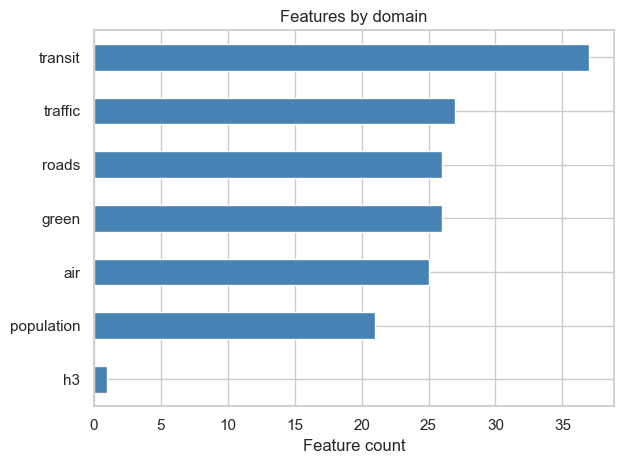

In [23]:
domains = pd.Series(clean.columns.str.split('_').str[0]).value_counts().sort_values()
domains.plot.barh(color='steelblue')
plt.title('Features by domain')
plt.xlabel('Feature count')
plt.tight_layout()
plt.show()

### 4.2 Spatial distribution of H3 cells

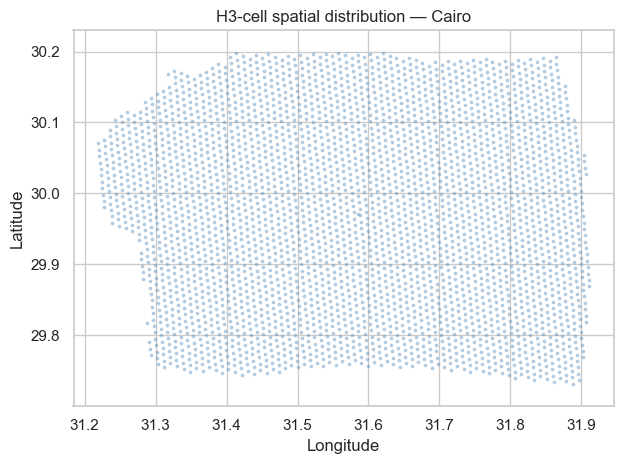

In [24]:
plt.scatter(clean.roads_longitude, clean.roads_latitude, s=3, alpha=.3, c='steelblue')
plt.title('H3-cell spatial distribution — Cairo')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('equal')
plt.tight_layout()
plt.show()

### 4.3 Population distribution

In [25]:
population = clean['population_population_worldpop_2026']
print(population.describe())

count     3489.0000
mean      3336.2515
std      11375.1606
min          0.0000
25%          2.4968
50%         29.4607
75%        305.0359
max     108627.8585
Name: population_population_worldpop_2026, dtype: float64


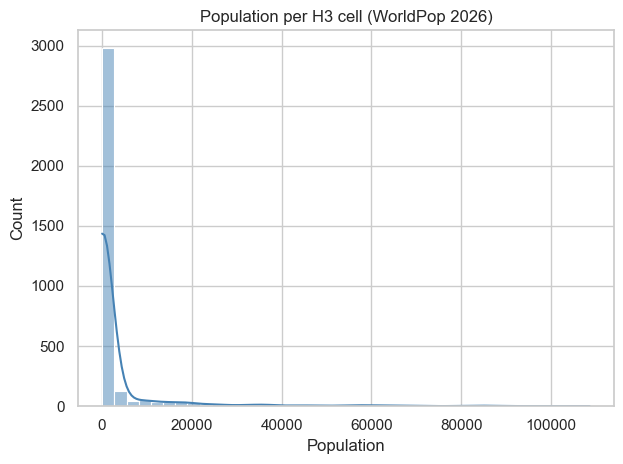

In [26]:
sns.histplot(population, bins=40, kde=True, color='steelblue')
plt.title('Population per H3 cell (WorldPop 2026)')
plt.xlabel('Population')
plt.tight_layout()
plt.show()

### 4.4 Population density distribution

In [27]:
density = clean['population_population_density_worldpop_2026']
print(density.describe())

count     3489.0000
mean      4242.5006
std      14082.0011
min          0.0000
25%          3.0000
50%         34.5200
75%        379.7100
max     133933.2900
Name: population_population_density_worldpop_2026, dtype: float64


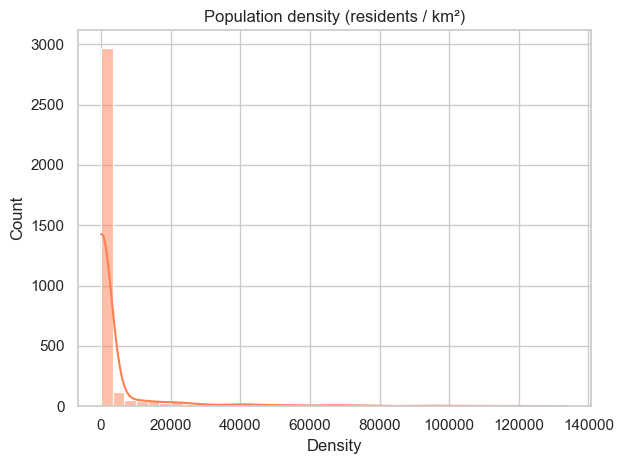

In [28]:
sns.histplot(density, bins=40, kde=True, color='coral')
plt.title('Population density (residents / km²)')
plt.xlabel('Density')
plt.tight_layout()
plt.show()

### 4.5 Population vs density

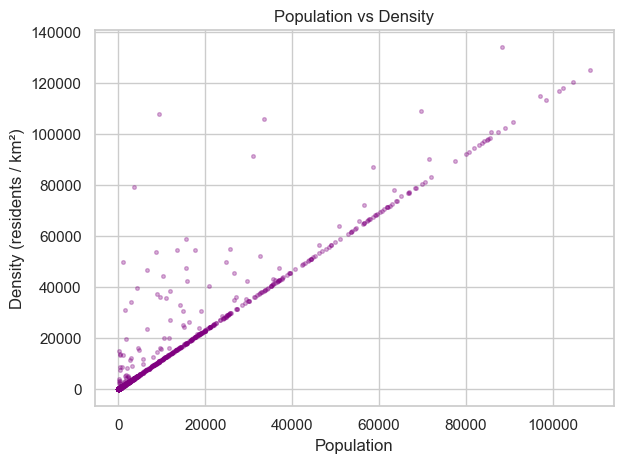

In [29]:
plt.scatter(population, density, s=7, alpha=.3, c='purple')
plt.title('Population vs Density')
plt.xlabel('Population')
plt.ylabel('Density (residents / km²)')
plt.tight_layout()
plt.show()

### 4.6 Road length distribution

In [30]:
road_length = clean['roads_road_length_km']
print(road_length.describe())

count   3489.0000
mean       6.9137
std        8.8392
min        0.0000
25%        0.0000
50%        2.5085
75%       11.8710
max       43.1710
Name: roads_road_length_km, dtype: float64


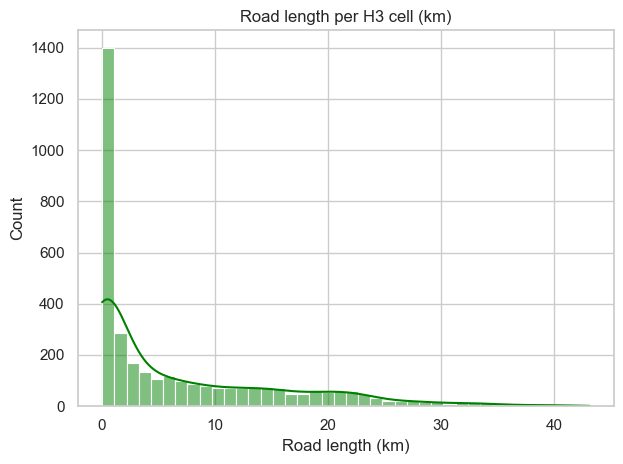

In [31]:
sns.histplot(road_length, bins=40, kde=True, color='green')
plt.title('Road length per H3 cell (km)')
plt.xlabel('Road length (km)')
plt.tight_layout()
plt.show()

### 4.7 Road density distribution

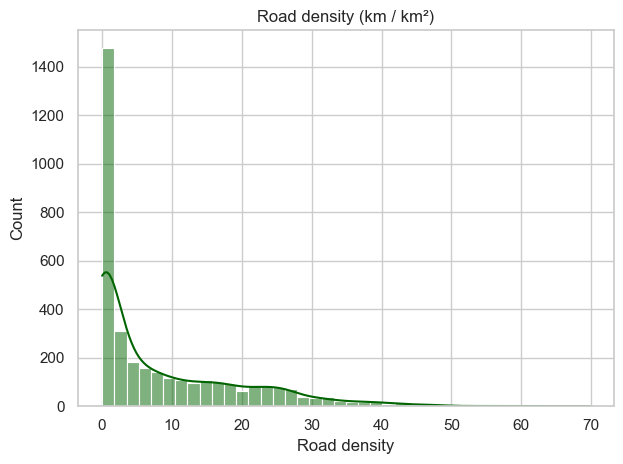

In [32]:
road_density = clean['roads_road_density_km_per_km2']
sns.histplot(road_density, bins=40, kde=True, color='darkgreen')
plt.title('Road density (km / km²)')
plt.xlabel('Road density')
plt.tight_layout()
plt.show()

### 4.8 Population vs road length

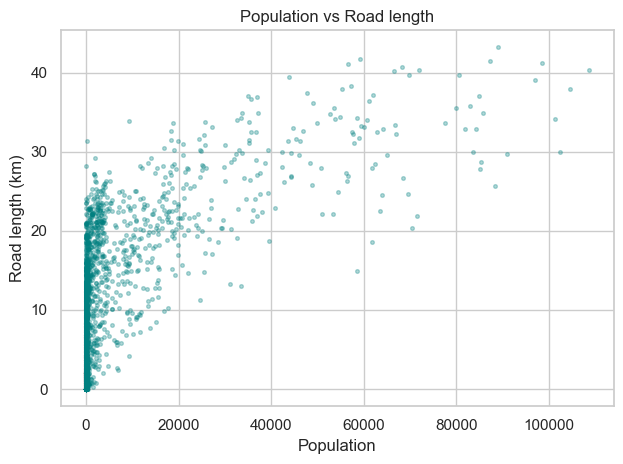

In [33]:
plt.scatter(population, road_length, s=7, alpha=.3, c='teal')
plt.title('Population vs Road length')
plt.xlabel('Population')
plt.ylabel('Road length (km)')
plt.tight_layout()
plt.show()

### 4.9 Transit availability

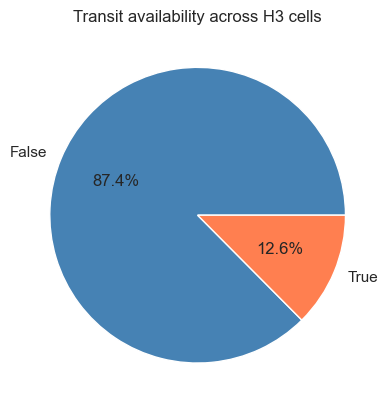

In [34]:
transit_avail = clean['transit_has_transit'].value_counts()
transit_avail.plot.pie(autopct='%1.1f%%', ylabel='', colors=['steelblue', 'coral'])
plt.title('Transit availability across H3 cells')
plt.show()

### 4.10 Transit stop count

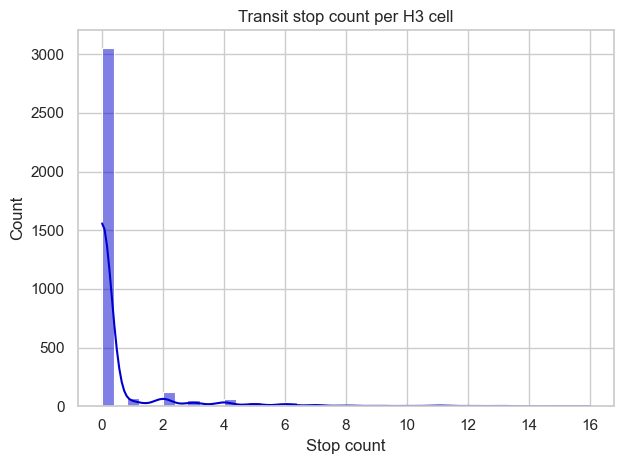

In [35]:
stops = clean['transit_transit_stop_count']
sns.histplot(stops, bins=40, kde=True, color='mediumblue')
plt.title('Transit stop count per H3 cell')
plt.xlabel('Stop count')
plt.tight_layout()
plt.show()

### 4.11 Nearest transit stop distance

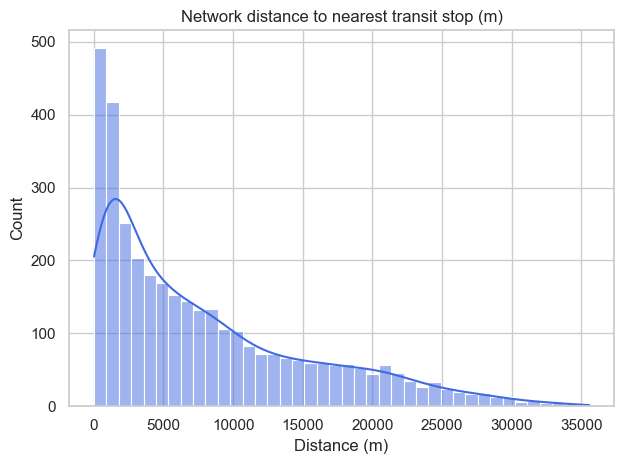

In [36]:
distance = clean['transit_nearest_transit_stop_network_distance_m']
sns.histplot(distance, bins=40, kde=True, color='royalblue')
plt.title('Network distance to nearest transit stop (m)')
plt.xlabel('Distance (m)')
plt.tight_layout()
plt.show()

### 4.12 Distance to stop vs transit accessibility score

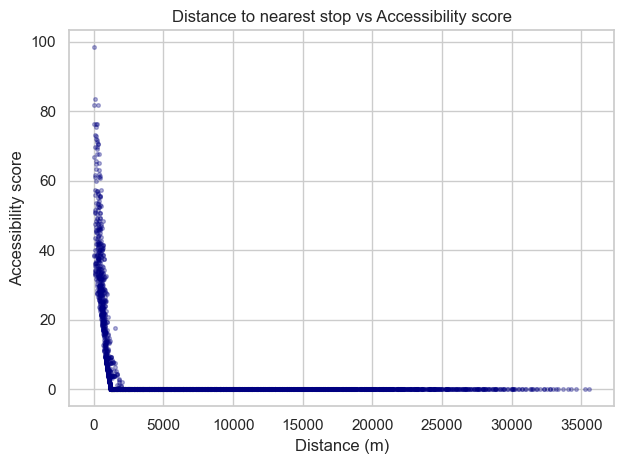

In [37]:
access = clean['transit_transit_accessibility_score']
plt.scatter(distance, access, s=7, alpha=.3, c='navy')
plt.title('Distance to nearest stop vs Accessibility score')
plt.xlabel('Distance (m)')
plt.ylabel('Accessibility score')
plt.tight_layout()
plt.show()

### 4.13 NO2 distribution

In [38]:
no2 = clean['air_quality_s5p_no2_tropospheric_column_mean_umol_m2']
print(no2.describe())

count   3489.0000
mean     135.9618
std       60.1920
min       36.4650
25%       94.0950
50%      123.0495
75%      165.2770
max      310.8090
Name: air_quality_s5p_no2_tropospheric_column_mean_umol_m2, dtype: float64


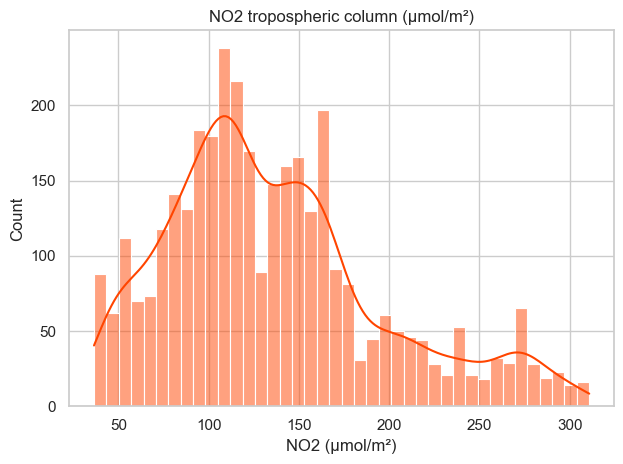

In [39]:
sns.histplot(no2, bins=40, kde=True, color='orangered')
plt.title('NO2 tropospheric column (µmol/m²)')
plt.xlabel('NO2 (µmol/m²)')
plt.tight_layout()
plt.show()

### 4.14 Road density vs NO2

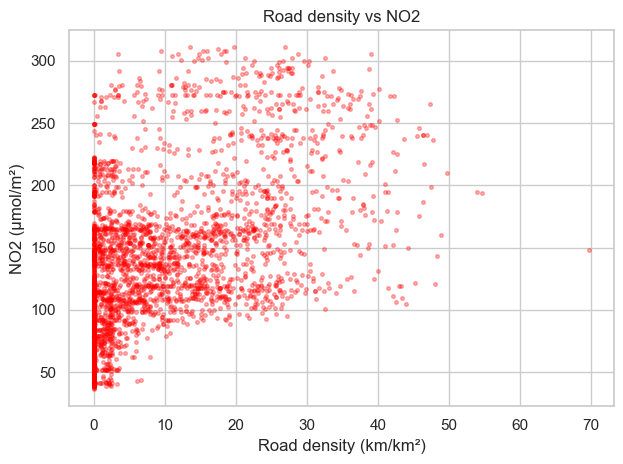

In [40]:
plt.scatter(road_density, no2, s=7, alpha=.3, c='red')
plt.title('Road density vs NO2')
plt.xlabel('Road density (km/km²)')
plt.ylabel('NO2 (µmol/m²)')
plt.tight_layout()
plt.show()

### 4.15 Population vs NO2

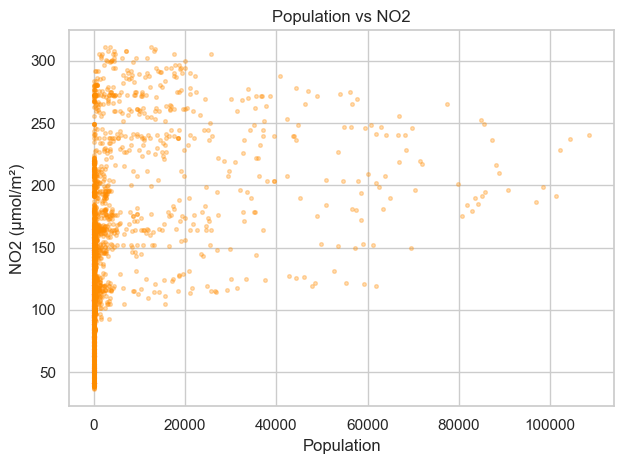

In [41]:
plt.scatter(population, no2, s=7, alpha=.3, c='darkorange')
plt.title('Population vs NO2')
plt.xlabel('Population')
plt.ylabel('NO2 (µmol/m²)')
plt.tight_layout()
plt.show()

### 4.16 NDVI distribution

In [42]:
ndvi = clean['green_space_ndvi_mean_annual_2026']
print(ndvi.describe())

count   3489.0000
mean       0.0703
std        0.0287
min       -0.0775
25%        0.0562
50%        0.0611
75%        0.0706
max        0.3384
Name: green_space_ndvi_mean_annual_2026, dtype: float64


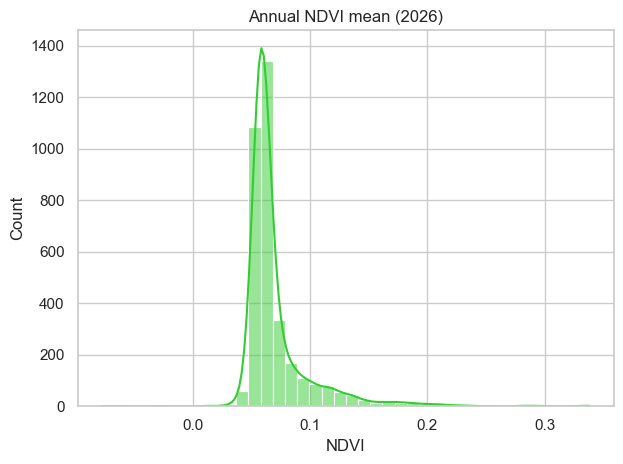

In [43]:
sns.histplot(ndvi, bins=40, kde=True, color='limegreen')
plt.title('Annual NDVI mean (2026)')
plt.xlabel('NDVI')
plt.tight_layout()
plt.show()

### 4.17 NDVI vs NO2

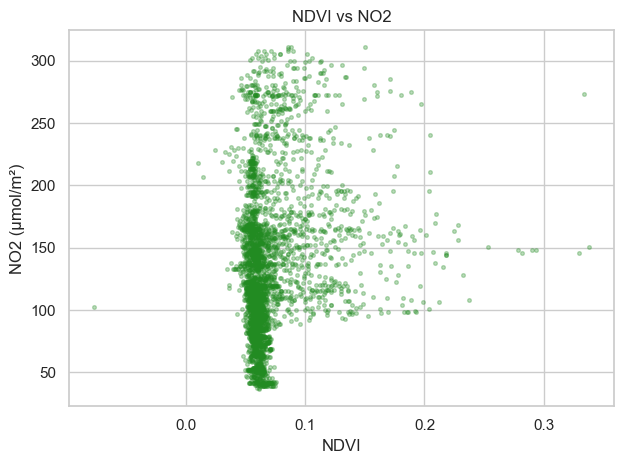

In [44]:
plt.scatter(ndvi, no2, s=7, alpha=.3, c='forestgreen')
plt.title('NDVI vs NO2')
plt.xlabel('NDVI')
plt.ylabel('NO2 (µmol/m²)')
plt.tight_layout()
plt.show()

### 4.18 Public green space area

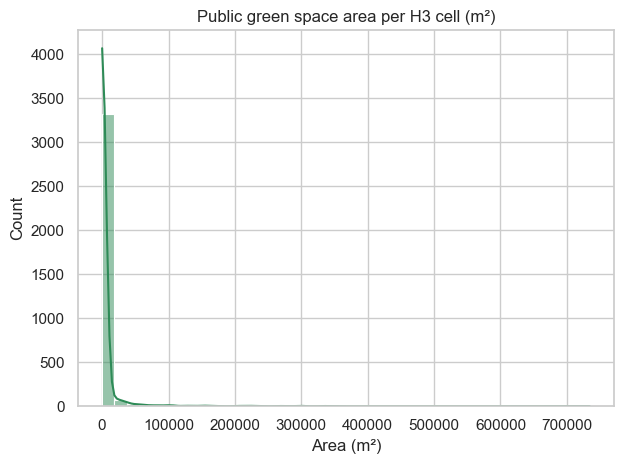

In [45]:
green = clean['green_space_public_green_space_area_m2']
sns.histplot(green, bins=40, kde=True, color='seagreen')
plt.title('Public green space area per H3 cell (m²)')
plt.xlabel('Area (m²)')
plt.tight_layout()
plt.show()

### 4.19 Traffic friction index distribution

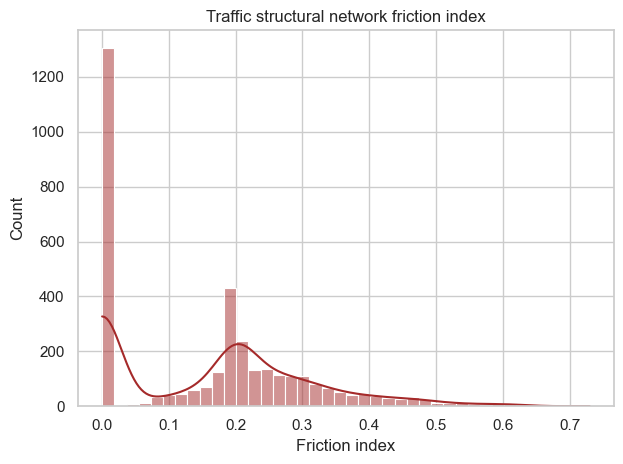

In [46]:
friction = clean['traffic_structural_network_friction_index']
sns.histplot(friction, bins=40, kde=True, color='brown')
plt.title('Traffic structural network friction index')
plt.xlabel('Friction index')
plt.tight_layout()
plt.show()

### 4.20 Correlation heatmap — top 25 high-variance features

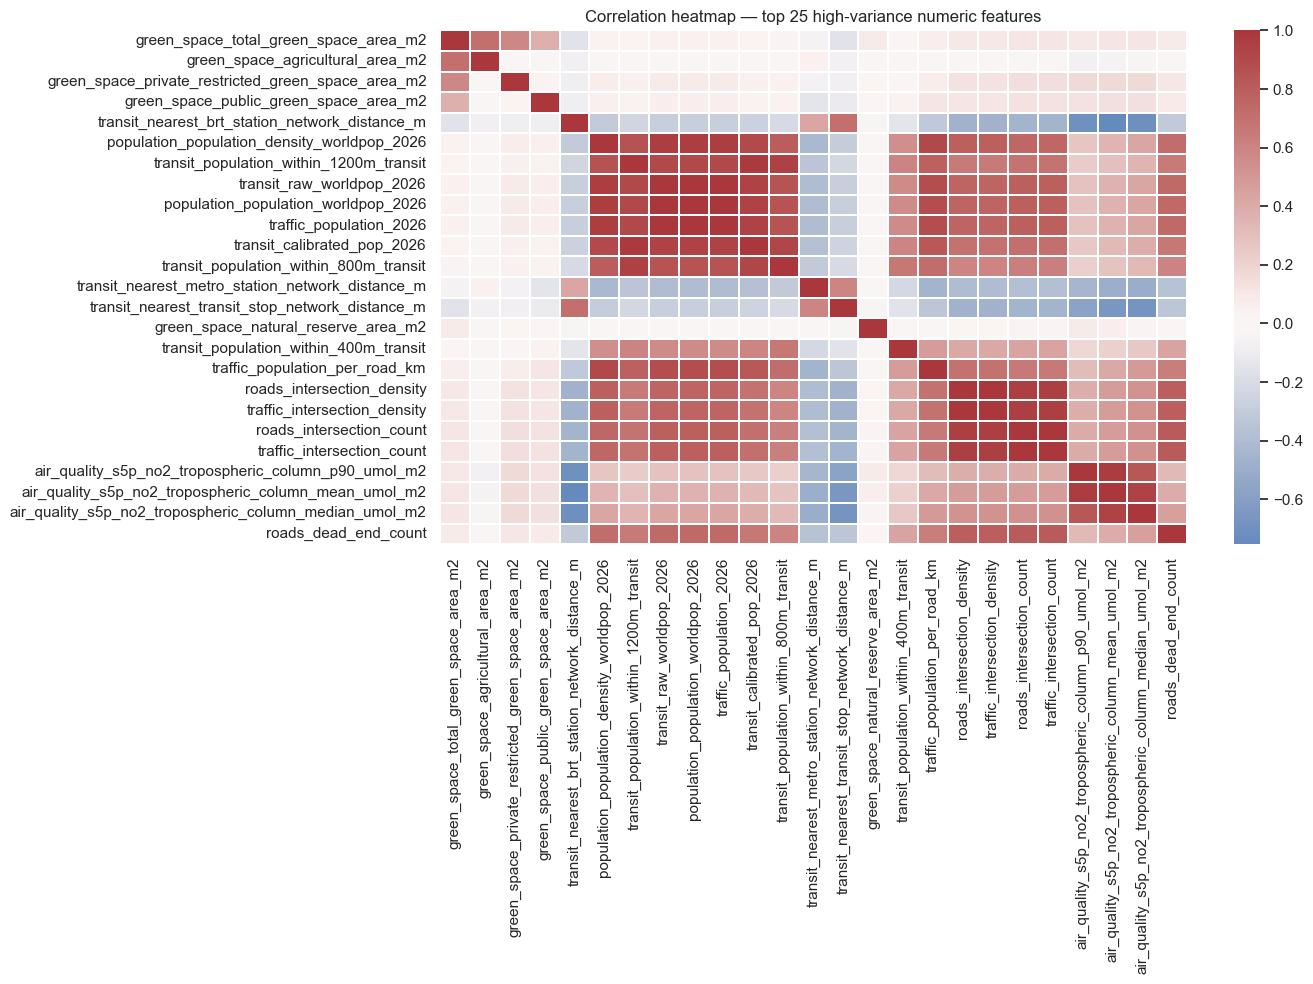

In [47]:
num_clean = clean.select_dtypes(include=np.number).columns.tolist()
top_var = clean[num_clean].var().sort_values(ascending=False).head(25).index
plt.figure(figsize=(14, 10))
sns.heatmap(clean[top_var].corr(), cmap='vlag', center=0,
            annot=False, linewidths=0.3)
plt.title('Correlation heatmap — top 25 high-variance numeric features')
plt.tight_layout()
plt.show()

## 5. Preprocessing & Feature Engineering

Transform the clean dataset into a numeric, model-ready feature matrix.

| Step | Action |
|------|--------|
| 5.1 | Define & drop metadata / ID columns |
| 5.2 | Drop constant / near-constant columns |
| 5.3 | Build feature frame `X` |
| 5.4 | Encode boolean columns → 0/1 |
| 5.5 | One-hot encode low-cardinality categoricals |
| 5.6 | Drop remaining high-cardinality text columns |
| 5.7 | Log-transform skewed numeric features |
| 5.8 | Validate (no NaN / Inf) |

### 5.1 Define metadata / ID columns to drop

In [48]:
META_TOKENS = (
    'source', 'url', 'doi', 'date', 'version', 'crs', 'grid',
    'analytical_grid', 'reference_year', 'observation_start', 'observation_end',
    'source_type', 'source_version', 'quality_flag', 'production_date',
    'snapshot_date', 'source_dataset', 'spatial_resolution_m',
    'native_spatial_resolution', 'source_url', 'population_type',
    'is_observed', 'is_estimated', 'is_derived', 'data_status',
    'index_available', 'coverage_flag',
)

meta_drop = [c for c in clean.columns
             if c == 'h3_index'
             or any(t in c.lower() for t in META_TOKENS)]
print(f'Metadata columns to drop ({len(meta_drop)}):')
print(meta_drop)

Metadata columns to drop (43):
['h3_index', 'population_reference_year', 'population_source', 'population_source_version', 'population_source_dataset', 'population_spatial_resolution_m', 'population_analytical_grid', 'population_crs', 'population_population_type', 'population_is_observed', 'population_is_estimated', 'population_quality_flag', 'population_production_date', 'population_doi', 'population_source_url', 'roads_reference_year', 'roads_source', 'roads_snapshot_date', 'roads_analytical_grid', 'traffic_structural_index_available', 'traffic_demand_capacity_index_available', 'traffic_combined_index_available', 'traffic_index_coverage_flag', 'traffic_reference_year', 'traffic_source_type', 'traffic_quality_flag', 'transit_reference_year', 'transit_analytical_grid', 'air_quality_s5p_no2_quality_flag', 'air_quality_pm25_station_coverage_flag', 'air_quality_pm10_station_coverage_flag', 'air_quality_reference_year', 'air_quality_observation_start', 'air_quality_observation_end', 'air_q

### 5.2 Drop constant / near-constant columns

In [49]:
const_drop = [c for c in clean.columns
              if c not in meta_drop
              and clean[c].nunique(dropna=False) <= 1]
print(f'Constant columns to drop ({len(const_drop)}): {const_drop}')

Constant columns to drop (1): ['traffic_tunnel_ratio_norm']


### 5.3 Build feature frame X

In [50]:
all_drop = list(set(meta_drop + const_drop))
X = clean[[c for c in clean.columns if c not in all_drop]].copy()
print(f'Feature frame shape: {X.shape}')

Feature frame shape: (3489, 119)


### 5.4 Encode boolean columns → 0/1 integers

In [51]:
bool_cols = X.select_dtypes(include='bool').columns.tolist()
X[bool_cols] = X[bool_cols].astype(int)
print(f'Boolean columns encoded ({len(bool_cols)}): {bool_cols}')

Boolean columns encoded (4): ['transit_has_transit', 'transit_multimodal_hub_present', 'transit_fallback_flag', 'green_space_has_public_green_space']


### 5.5 One-hot encode low-cardinality categorical columns

In [52]:
cat_cols    = X.select_dtypes(include='object').columns.tolist()
low_card    = [c for c in cat_cols if X[c].nunique() <= 10]
high_card   = [c for c in cat_cols if X[c].nunique() >  10]
print(f'Low-cardinality  (encode, <= 10 unique): {low_card}')
print(f'High-cardinality (drop,    > 10 unique): {high_card}')

Low-cardinality  (encode, <= 10 unique): ['traffic_structural_susceptibility_class', 'transit_district_assignment_method']
High-cardinality (drop,    > 10 unique): ['transit_district', 'air_quality_nearest_station_id', 'air_quality_nearest_station_name']


In [53]:
X = pd.get_dummies(X, columns=low_card, drop_first=True, dtype=int)
print(f'Shape after OHE: {X.shape}')

Shape after OHE: (3489, 122)


### 5.6 Drop remaining high-cardinality text columns

In [54]:
remaining_cat = X.select_dtypes(include='object').columns.tolist()
X = X.drop(columns=remaining_cat)
print(f'Dropped: {remaining_cat}')
print(f'Shape after dropping high-cardinality cols: {X.shape}')

Dropped: ['transit_district', 'air_quality_nearest_station_id', 'air_quality_nearest_station_name']
Shape after dropping high-cardinality cols: (3489, 119)


### 5.7 Log-transform heavily skewed numeric features

In [55]:
from scipy.stats import skew

num_feat = X.select_dtypes(include=np.number).columns.tolist()
skewness = X[num_feat].apply(lambda c: skew(c.dropna()))
skewed_cols = skewness[skewness.abs() > 1].index.tolist()
print(f'Features with |skewness| > 1: {len(skewed_cols)}')
print(skewed_cols[:15], '...' if len(skewed_cols) > 15 else '')

Features with |skewness| > 1: 94
['population_population_worldpop_2026', 'population_population_density_worldpop_2026', 'population_area_km2', 'population_cairo_intersection_ratio', 'roads_area_km2', 'roads_road_length_km', 'roads_road_density_km_per_km2', 'roads_motorway_length_km', 'roads_trunk_length_km', 'roads_primary_road_length_km', 'roads_secondary_road_length_km', 'roads_tertiary_road_length_km', 'roads_residential_road_length_km', 'roads_service_road_length_km', 'roads_other_road_length_km'] ...


In [56]:
# log1p is safe for columns that can contain zero
log_applied = []
for col in skewed_cols:
    if (X[col] >= 0).all():
        X[col] = np.log1p(X[col])
        log_applied.append(col)
print(f'log1p applied to {len(log_applied)} columns.')

log1p applied to 88 columns.


### 5.8 Validate — no NaN or Inf in feature frame

In [57]:
bad = X.replace([np.inf, -np.inf], np.nan).isna().sum()
bad = bad[bad > 0]
if len(bad) == 0:
    print('Feature frame is clean — no NaN or Inf values.')
else:
    print('Problematic columns:')
    display(bad.to_frame('issues'))

Feature frame is clean — no NaN or Inf values.


## 6. Final Model-Ready Data

| Step | Action |
|------|--------|
| 6.1 | Set target variable |
| 6.2 | Separate features and target |
| 6.3 | Spatial train/test split (70/30) |
| 6.4 | StandardScaler normalisation |
| 6.5 | Summary |
| 6.6 | Random Forest baseline |

### 6.1 Set target variable

In [58]:
# ----------------------------------------------------------------
# Change TARGET to any numeric column you want to predict.
# Regression examples:
#   'transit_transit_accessibility_score'
#   'air_quality_s5p_no2_tropospheric_column_mean_umol_m2'
#   'traffic_structural_network_friction_index'
#   'green_space_total_green_space_fraction'
# ----------------------------------------------------------------
TARGET       = 'transit_transit_accessibility_score'
RANDOM_STATE = 42
print(f'Target: {TARGET}')

Target: transit_transit_accessibility_score


### 6.2 Separate features and target

In [59]:
if TARGET not in X.columns:
    # Re-attach from clean if it was dropped during preprocessing
    X[TARGET] = clean.loc[X.index, TARGET].values
    print('Target re-attached from clean frame.')

y      = X[TARGET].copy()
X_feat = X.drop(columns=[TARGET])
print(f'Features: {X_feat.shape}  |  Target: {y.shape}')
print(y.describe())

Features: (3489, 118)  |  Target: (3489,)
count   3489.0000
mean       0.5659
std        1.2145
min        0.0000
25%        0.0000
50%        0.0000
75%        0.0000
max        4.5992
Name: transit_transit_accessibility_score, dtype: float64


### 6.3 Spatial train/test split (70 / 30)

> **Why spatial split?** Urban data has strong spatial autocorrelation —
> neighbouring cells are very similar. A random split would allow the model
> to 'memorise' local patterns, inflating apparent accuracy.
> Splitting by rounded-coordinate blocks ensures the test set is
> **geographically separated** from training.

In [60]:
lat_col = 'roads_latitude'
lon_col = 'roads_longitude'

blocks = (clean.loc[X_feat.index, lat_col].round(2).astype(str)
          + '|' +
          clean.loc[X_feat.index, lon_col].round(2).astype(str))

u = np.array(sorted(blocks.unique()))
np.random.default_rng(RANDOM_STATE).shuffle(u)
train_blocks = set(u[:int(.7 * len(u))])

split = pd.Series(
    np.where(blocks.isin(train_blocks), 'train', 'test'),
    index=X_feat.index,
)
print(f'Train: {split.eq("train").sum()} rows  |  Test: {split.eq("test").sum()} rows')

Train: 2422 rows  |  Test: 1067 rows


### 6.4 StandardScaler normalisation

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_raw = X_feat.loc[split.eq('train')]
X_test_raw  = X_feat.loc[split.eq('test')]
y_train     = y.loc[split.eq('train')]
y_test      = y.loc[split.eq('test')]

X_train = pd.DataFrame(scaler.fit_transform(X_train_raw),
                        columns=X_train_raw.columns,
                        index=X_train_raw.index)
X_test  = pd.DataFrame(scaler.transform(X_test_raw),
                        columns=X_test_raw.columns,
                        index=X_test_raw.index)
print(f'X_train: {X_train.shape}  |  X_test: {X_test.shape}')

X_train: (2422, 118)  |  X_test: (1067, 118)


### 6.5 Data pipeline summary

In [62]:
print('=' * 55)
print(f'  Raw rows:           {len(df)}')
print(f'  After dedup:        {len(clean)}')
print(f'  Features (final):   {X_feat.shape[1]}')
print(f'  Target:             {TARGET}')
print(f'  Train samples:      {X_train.shape[0]}')
print(f'  Test samples:       {X_test.shape[0]}')
print(f'  Split ratio:        {X_train.shape[0]/len(X_feat)*100:.1f}% train / '
      f'{X_test.shape[0]/len(X_feat)*100:.1f}% test')
print('=' * 55)

  Raw rows:           3489
  After dedup:        3489
  Features (final):   118
  Target:             transit_transit_accessibility_score
  Train samples:      2422
  Test samples:       1067
  Split ratio:        69.4% train / 30.6% test


### 6.6 Random Forest baseline

In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics  import r2_score, mean_absolute_error

rf = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

r2  = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f'Random Forest baseline')
print(f'  R²  = {r2:.4f}')
print(f'  MAE = {mae:.4f}')

Random Forest baseline
  R²  = 0.9976
  MAE = 0.0171


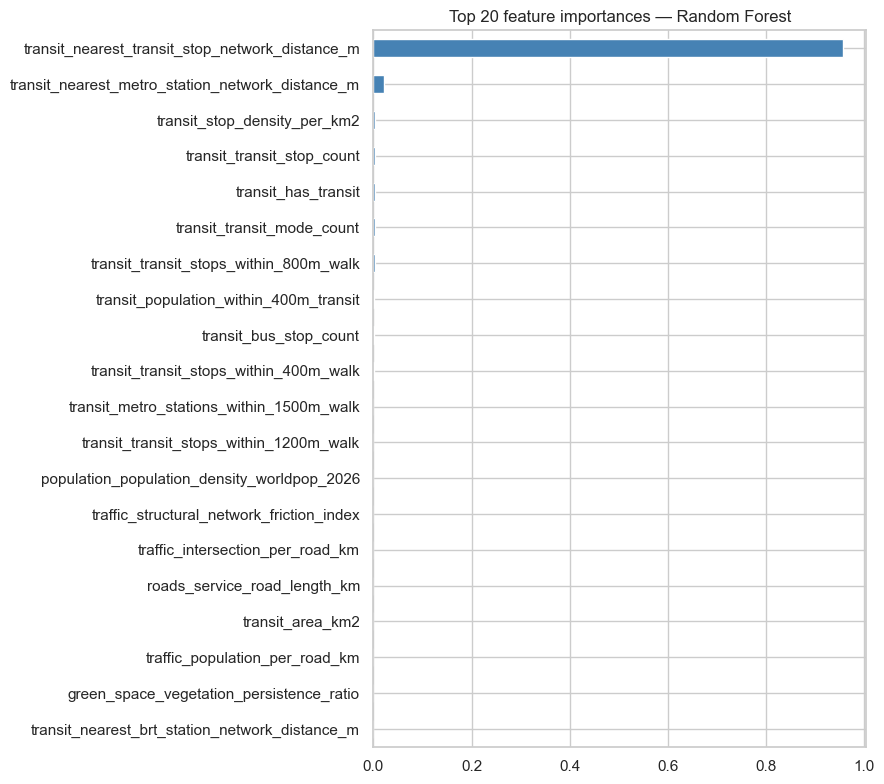

In [64]:
# Top-20 feature importances
importances = (pd.Series(rf.feature_importances_, index=X_train.columns)
               .sort_values(ascending=False).head(20))
importances.plot.barh(figsize=(9, 8), color='steelblue')
plt.title('Top 20 feature importances — Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 6.7 Objects ready for modelling

| Object | Description |
|--------|-------------|
| `X_train` | Scaled training features |
| `X_test`  | Scaled test features |
| `y_train` | Training target values |
| `y_test`  | Test target values |
| `scaler`  | Fitted `StandardScaler` |
| `split`   | 'train'/'test' label per row |
| `clean`   | Imputed, de-duplicated raw frame |

> Add your next model cells here.